# 第5章：金融标签——原趋势扫描与覆盖边界

## 统一实验约定
各章节在项目根目录独立运行，无需安装本项目。公共数据处理与实验辅助见 [notebook_common.py](notebook_common.py)，依赖集中在 [requirement.txt](requirement.txt)。

所有章节读取 `data/hs_funds_prices.parquet`，固定种子42。最近1,260个价格观测中，前1,008个用于训练，后252个用于测试。
`SelectComplete` 排除训练收益中的全部缺失；`DropZeroVariance` 的阈值换算后保持原口径：样本方差（`ddof=1`）大于 `1e-12`。默认使用全部合格基金，测试期不重新筛选资产。
先计算单日收益，再排除共同无效日期，不做填充。测试结果**不是连续、可交易的回测**；价格复权口径尚未确认。

初始化只展示数据摘要；完整资产和排除日期可按需查看 `data.assets`、`data.excluded_test_dates`。`ML4AM_SMOKE=1` 仅供自动化小样本验证，正常运行不设置。

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_common import load_data, setup_notebook, timed, quiet

SEED = 42
setup_notebook(SEED)
data = load_data()
X_train, X_test, assets = data.X_train, data.X_test, data.assets
prices = data.prices
display(data.summary())

数据模式                          全部合格基金
训练期合格基金数                         488
本次使用基金数                          488
训练收益行数                          1007
训练收益区间       2021-07-14 至 2025-09-04
测试候选区间       2025-09-05 至 2026-09-18
测试候选日期数                          252
测试共同有效日期数                        124
排除测试日期数                          128
测试日期覆盖率                       49.21%
Name: 数据概览, dtype: object

## 1. 原函数与单序列示例
skfolio 1.9.11没有趋势扫描/三重障碍标签接口。本章不伪造对应实现。
[原脚本](Machine_Learning_for_Asset_Managers/ch5_financial_labels.py)实际实现的是回溯趋势扫描。
使用固定基金集合中排序第一只，全部窗口价格；原函数依赖整数索引，因此输入前重置索引。
函数返回的`t1`把整数位置转换为纳秒时间，并不是交易日期；后面单独解释修正口径。

In [2]:
from Machine_Learning_for_Asset_Managers import ch5_financial_labels as original
asset = assets[0]
close = prices[asset].reset_index(drop=True)
SPAN = (5, 21, 1)
original_labels, elapsed = timed(f'原趋势扫描：{asset}', lambda: quiet(
    lambda: original.getBinsFromTrend(close.index, close, SPAN)))
display(original_labels.head())
print('原t统计量示例：', original.tValLinR(close.iloc[:20].to_numpy()))

开始：原趋势扫描：159001.SZ


原函数日志共3720行，末尾： 5
1240
1255
5
完成：原趋势扫描：159001.SZ，耗时 10.42 秒


,t1,tVal,bin,windowSize
20,1970-01-01 00:00:00.000000001,2.236068,1.0,11
21,1970-01-01 00:00:00.000000002,2.146247,1.0,12
22,1970-01-01 00:00:00.000000003,-3.162278,-1.0,6
23,1970-01-01 00:00:00.000000004,-4.417706,-1.0,7
24,1970-01-01 00:00:00.000000005,-2.140129,-1.0,8


原t统计量示例： 1.6238399201934157


## 2. 日期对齐与可解释的局部复现（不是skfolio）
沿用原 `tValLinR` 和最大绝对t值选窗口规则；显式保留真实窗口开始/结束时间与未截尾t值。
原函数的`t1`不是实际选中窗口、`windowSize`对非单位步长也有局限；
这些语义差异与pandas兼容性不同，不能悄悄当作原输出。原t值裁剪仅用于绘图，不解释为置信概率。

与原实现方向一致比例： 1.0


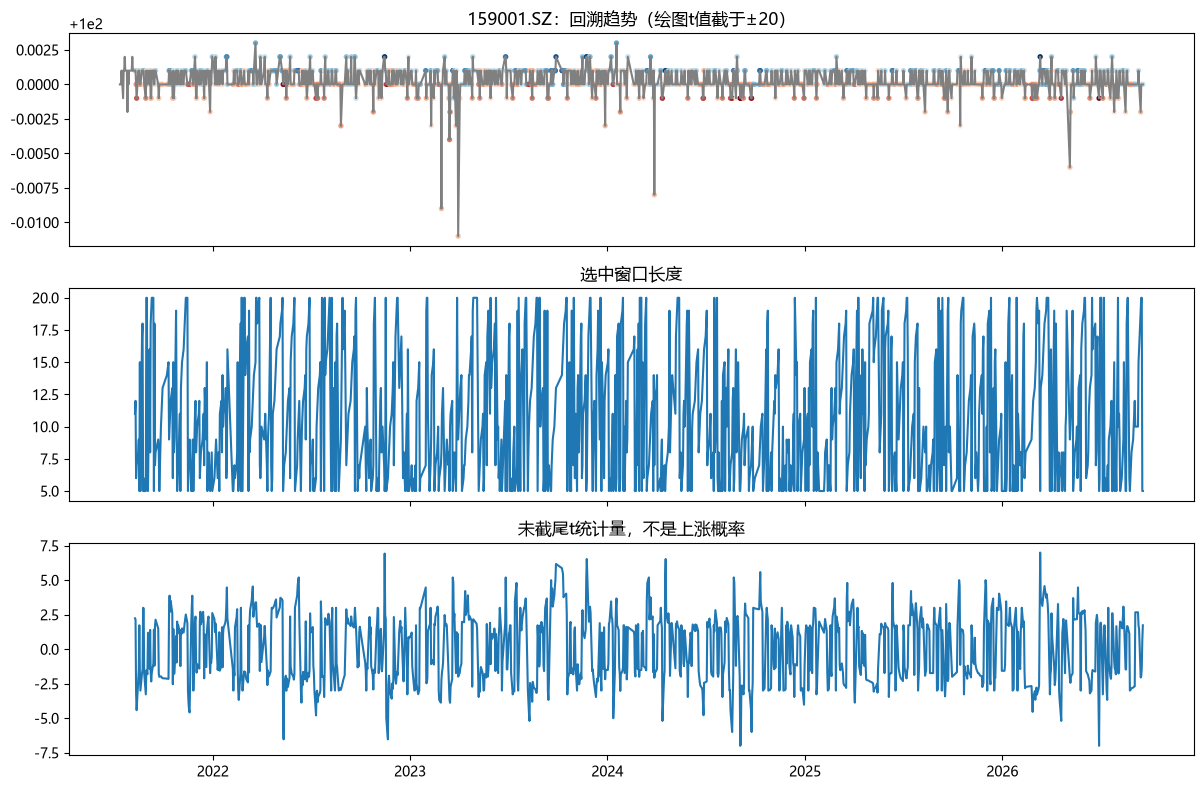

,窗口开始,窗口结束,窗口长度,原始t值,方向
日期,,,,,
2026-09-14 00:00:00+08:00,2026-08-19 00:00:00+08:00,2026-09-14 00:00:00+08:00,19,-2.048530,-1.0
2026-09-15 00:00:00+08:00,2026-08-19 00:00:00+08:00,2026-09-15 00:00:00+08:00,20,-1.959057,-1.0
2026-09-16 00:00:00+08:00,2026-08-20 00:00:00+08:00,2026-09-16 00:00:00+08:00,20,-1.338124,-1.0
2026-09-17 00:00:00+08:00,2026-09-11 00:00:00+08:00,2026-09-17 00:00:00+08:00,5,0.654654,1.0
2026-09-18 00:00:00+08:00,2026-09-14 00:00:00+08:00,2026-09-18 00:00:00+08:00,5,1.732051,1.0


In [3]:
rows = []
for end in range(SPAN[1]-1, len(close)):
    candidates = []
    for horizon in range(*SPAN):
        value = original.tValLinR(close.iloc[end-horizon+1:end+1].to_numpy())
        candidates.append(value if np.isfinite(value) else 0.0)
    best = int(np.argmax(np.abs(candidates)))
    horizon = list(range(*SPAN))[best]
    rows.append({'日期': prices.index[end], '窗口开始': prices.index[end-horizon+1],
                 '窗口结束': prices.index[end], '窗口长度': horizon,
                 '原始t值': candidates[best], '方向': np.sign(candidates[best])})
labels = pd.DataFrame(rows).set_index('日期')
old_bin = pd.to_numeric(original_labels['bin']).to_numpy()
print('与原实现方向一致比例：', np.mean(old_bin == labels['方向'].to_numpy()))
assert len(labels) == len(original_labels)
np.testing.assert_array_equal(old_bin, labels['方向'].to_numpy())
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(prices.index, prices[asset], color='gray')
scatter = axes[0].scatter(labels.index, prices.loc[labels.index, asset], c=labels['原始t值'].clip(-20, 20), cmap='RdBu', s=8)
axes[0].set_title(f'{asset}：回溯趋势（绘图t值截于±20）')
axes[1].plot(labels.index, labels['窗口长度']); axes[1].set_title('选中窗口长度')
axes[2].plot(labels.index, labels['原始t值']); axes[2].set_title('未截尾t统计量，不是上涨概率')
plt.tight_layout(); plt.show()
display(labels.tail())

## 结论与信息时点
该信号在当日收盘之后才完整可知，若用于交易必须考虑下一可交易时点；
不能用它解释同日已发生的收益。若改成书中前视标签，应按未来标签结束时间进行purge/embargo。
第6章另行使用下一日方向标签，不将这里的回溯标签冒充未来收益标签。
本章单资产示例不意味着其他章节缩减了全资产集合。